# Diagnóstico y mejoras de los modelos explicables

<a href="https://colab.research.google.com/github/Niettzche/spaceapps-2026/blob/main/ciencia_datos/02_diagnostico_y_mejoras.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

El notebook `01` llegó a 55 % de exactitud balanceada (al azar: 33 %). Aquí revisamos por qué no da más y qué lo mejora, una pregunta a la vez:

1. **¿Atendimos el desbalance?** (4,288 Luna, 284 Marte, 47 Tierra)
2. **¿Usamos datos que no sirven?** Etiquetas de la Tierra, cráteres demasiado pequeños para medirlos bien, anillo lunar.
3. **Cambiar la pregunta:** entrenar solo con Luna y Marte (datos limpios) y usar ese modelo para juzgar a México, sin depender de etiquetas terrestres.

Todas las cifras son **10 repeticiones** de validación cruzada por grupos espaciales (5 pliegues), así que cada número trae su variación (±).

In [1]:
import subprocess
from pathlib import Path
REPO, RUTA = "Niettzche/spaceapps-2026", "ciencia_datos/datos"
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / RUTA / "crateres_mexico.csv").exists()), None)
if RAIZ is None:
    try:
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{REPO}.git"
    except Exception:
        url = f"https://github.com/{REPO}.git"
    subprocess.run(["git", "clone", "--depth", "1", url, "/content/spaceapps-2026"], check=True)
    RAIZ = Path("/content/spaceapps-2026")
DATOS, SALIDA = RAIZ / RUTA, RAIZ / "ciencia_datos" / "salidas"
SALIDA.mkdir(parents=True, exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings("ignore")
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score
from sklearn.covariance import MinCovDet

COLORES = {"Luna": "#8a8f98", "Marte": "#b5532f", "Tierra": "#1f6f78"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
F = ["log_diam", "prof_diam", "borde_rel", "relleno", "aspecto"]

def preparar(d):
    d = d.copy(); d["log_diam"] = np.log10(d.diam_km); d["borde_rel"] = d.borde_m / (d.diam_km * 1000); return d
ref, mx = pd.read_csv(DATOS / "hoyas_referencia.csv"), pd.read_csv(DATOS / "crateres_mexico.csv")
r = preparar(ref[ref.crater])
r["grupo"] = r.cuerpo + "|" + r.sitio + "|" + (r.i // 250).astype(int).astype(str) + "_" + (r.j // 250).astype(int).astype(str)
m = preparar(mx); m["cuerpo"], m["sitio"] = "Tierra", "México"
m["grupo"] = "T|" + m.br.astype(str) + "_" + m.bc.astype(str)
m["arida"] = m.ndvi_p90 < 0.35
m["verificado"] = m.nombre.notna() | (m.tipo == "mina")      # cráteres con nombre (Pinacate, Guanajuato) o tajos mineros
COLS = F + ["cuerpo", "sitio", "grupo", "area_px", "tipo"]
r["tipo"] = ""

def evaluar(datos, modelo, feats=F, reps=10, muestreo=None):
    # Validación cruzada por grupos repetida; devuelve media y desviación de la exactitud balanceada y el acierto por clase
    X, y, g = datos[feats].to_numpy(float), datos.cuerpo.to_numpy(object), datos.grupo.to_numpy(object)
    clases = sorted(set(y)); ba, rec = [], {c: [] for c in clases}
    for s in range(reps):
        pred = np.empty(len(y), object)
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, g):
            if muestreo is not None:
                tr = muestreo(tr, y, s)
            modelo.fit(X[tr], y[tr]); pred[te] = modelo.predict(X[te])
        ba.append(balanced_accuracy_score(y, pred))
        for c in clases: rec[c].append((pred[y == c] == c).mean())
    return {"exactitud balanceada": np.mean(ba), "±": np.std(ba), **{f"acierto {c}": np.mean(v) for c, v in rec.items()}}

arbol = lambda w="balanced": DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, class_weight=w, random_state=0)
logistica = lambda w="balanced": make_pipeline(StandardScaler(), LogisticRegression(class_weight=w, max_iter=3000))
fmt = lambda t: t.style.format({c: "{:.0%}" for c in t.columns}) if hasattr(t, "style") else t
def tabla(filas):
    t = pd.DataFrame(filas).set_index("caso")
    return (t * 100).round(0).astype("Int64").astype(str) + " %"

base = pd.concat([r[COLS], m.loc[m.arida, COLS]], ignore_index=True)
print(base.cuerpo.value_counts().to_string())

cuerpo
Luna      4288
Marte      284
Tierra      47


## 1. ¿Atendimos el desbalance?

Sí: en el `01` usamos `class_weight="balanced"` (cada cráter terrestre pesa ~90 veces más que uno lunar) y medimos con exactitud balanceada. Aquí lo comprobamos contra dos alternativas: **sin pesos** y **submuestreo** (en cada pliegue, ninguna clase con más de 3 veces los casos de la menor, además de los pesos).

In [2]:
def submuestreo(tr, y, s):
    rng = np.random.default_rng(s); cls, n = np.unique(y[tr], return_counts=True); tope = 3 * n.min()
    return np.concatenate([rng.choice(tr[y[tr] == c], min(tope, (y[tr] == c).sum()), replace=False) for c in cls])

filas = []
for nombre, fabrica in [("árbol", arbol), ("logística", logistica)]:
    filas.append({"caso": f"{nombre}: sin pesos", **evaluar(base, fabrica(None))})
    filas.append({"caso": f"{nombre}: pesos balanceados (lo del 01)", **evaluar(base, fabrica())})
    filas.append({"caso": f"{nombre}: pesos + submuestreo", **evaluar(base, fabrica(), muestreo=submuestreo)})
t1 = tabla(filas); t1

,exactitud balanceada,±,acierto Luna,acierto Marte,acierto Tierra
caso,,,,,
árbol: sin pesos,39 %,2 %,99 %,17 %,0 %
árbol: pesos balanceados (lo del 01),50 %,3 %,66 %,55 %,30 %
árbol: pesos + submuestreo,50 %,3 %,62 %,57 %,32 %
logística: sin pesos,33 %,0 %,100 %,0 %,0 %
logística: pesos balanceados (lo del 01),56 %,1 %,51 %,67 %,51 %
logística: pesos + submuestreo,56 %,1 %,51 %,66 %,50 %


**Lectura.** Sin pesos el modelo dice "Luna" casi siempre (acierto en la Tierra 0 %). Con pesos ya queda corregido, y el submuestreo no agrega nada. **El desbalance está atendido y no es lo que nos limita.**

## 2. ¿Usamos datos que no sirven?

### 2a. Las etiquetas de la Tierra

De las 47 detecciones áridas, la revisión preliminar dice que unas 14 son cráteres o tajos reales; el resto son dolinas y cañadas. Probamos con solo los **verificados**: los que tienen nombre (Pinacate, Rincón de Parangueo) o son tajos mineros.

In [3]:
ver = pd.concat([r[COLS], m.loc[m.arida & m.verificado, COLS]], ignore_index=True)
print("Verificados:", int((ver.cuerpo == "Tierra").sum()), "→", m.loc[m.arida & m.verificado, "tipo"].value_counts().to_dict())
filas = [{"caso": "logística, Tierra = 47 áridas", **evaluar(base, logistica())},
         {"caso": "logística, Tierra = 15 verificados", **evaluar(ver, logistica())},
         {"caso": "árbol, Tierra = 47 áridas", **evaluar(base, arbol())},
         {"caso": "árbol, Tierra = 15 verificados", **evaluar(ver, arbol())}]
t2 = tabla(filas); t2

Verificados: 15 → {'mina': 10, 'con_borde': 4, 'sin_borde': 1}


,exactitud balanceada,±,acierto Luna,acierto Marte,acierto Tierra
caso,,,,,
"logística, Tierra = 47 áridas",56 %,1 %,51 %,67 %,51 %
"logística, Tierra = 15 verificados",70 %,1 %,58 %,81 %,72 %
"árbol, Tierra = 47 áridas",50 %,3 %,66 %,55 %,30 %
"árbol, Tierra = 15 verificados",68 %,2 %,62 %,71 %,71 %


**Lectura.** Con etiquetas limpias la exactitud balanceada salta de ~55 % a ~70 %: **la calidad de las etiquetas es el cuello de botella**, no el modelo. Pero ojo: 10 de los 15 verificados son tajos mineros, así que el modelo puede estar aprendiendo "mina" (muy honda, sin borde) más que "cráter terrestre". Por eso hace falta la revisión a mano de las 47 y, si se puede, más cráteres naturales.

### 2b. Cráteres demasiado pequeños para medir su forma

A 200 m por píxel, la mitad de los cráteres ocupa menos de 20 píxeles. Con tan pocos píxeles el `aspecto` y el `relleno` solo pueden tomar unos cuantos valores: es ruido de cuadrícula, no forma.

Fracción con menos de 20 píxeles: {'Luna': 0.5, 'Marte': 0.38, 'Tierra': 0.6}


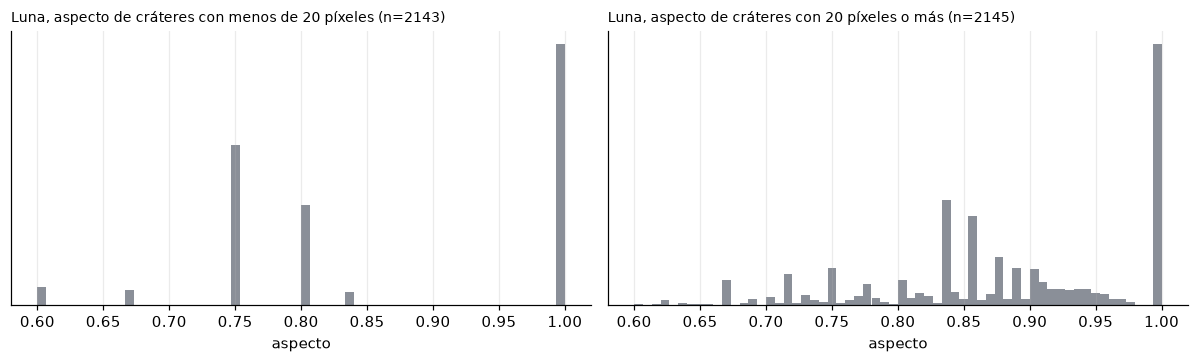

Medianas de relleno: {'Luna': 0.955, 'Marte': 0.935, 'Tierra': 0.849}


,exactitud balanceada,±,acierto Luna,acierto Marte,acierto Tierra
caso,,,,,
"logística, todos los tamaños",56 %,1 %,51 %,67 %,51 %
"logística, solo ≥ 20 píxeles (Tierra n=19)",59 %,2 %,62 %,60 %,54 %
"logística, sin aspecto",57 %,1 %,50 %,68 %,52 %
"logística, sin aspecto ni relleno",49 %,1 %,45 %,72 %,32 %


In [4]:
todo = pd.concat([r[COLS], m.loc[m.arida, COLS]])
print("Fracción con menos de 20 píxeles:", todo.groupby("cuerpo").apply(lambda d: (d.area_px < 20).mean()).round(2).to_dict())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (titulo, sel) in zip(axs, [("menos de 20 píxeles", todo.area_px < 20), ("20 píxeles o más", todo.area_px >= 20)]):
    d = todo[sel & (todo.cuerpo == "Luna")]
    ax.hist(d.aspecto, bins=60, color=COLORES["Luna"]); ax.set_title(f"Luna, aspecto de cráteres con {titulo} (n={len(d)})", fontsize=9, loc="left")
    ax.set_xlabel("aspecto"); ax.set_yticks([])
fig.tight_layout(); fig.savefig(SALIDA / "cuantizacion_aspecto.png", bbox_inches="tight"); plt.show()

grandes = base[base.area_px >= 20]
filas = [{"caso": "logística, todos los tamaños", **evaluar(base, logistica())},
         {"caso": f"logística, solo ≥ 20 píxeles (Tierra n={int((grandes.cuerpo == 'Tierra').sum())})", **evaluar(grandes, logistica())},
         {"caso": "logística, sin aspecto", **evaluar(base, logistica(), feats=["log_diam", "prof_diam", "borde_rel", "relleno"])},
         {"caso": "logística, sin aspecto ni relleno", **evaluar(base, logistica(), feats=["log_diam", "prof_diam", "borde_rel"])}]
print("Medianas de relleno:", base.groupby("cuerpo").relleno.median().round(3).to_dict())
t3 = tabla(filas); t3

**Lectura.** Quitar los cráteres chicos mejora un poco, pero deja muy pocos terrestres. El `aspecto` no aporta nada (es casi pura cuadrícula). El `relleno` sí ayuda, pero solo a reconocer a la Tierra: sin él la exactitud baja de 56 % a 49 %. La Tierra tiene relleno más bajo (0.85 contra 0.95 de la Luna), es decir, hoyas más irregulares. Eso cuadra con dolinas y tajos más que con cráteres de impacto, así que el modelo reconoce "depresión terrestre irregular", no "cráter terrestre". Para medir la forma en planta en serio habría que bajar a 100 m o menos donde los tres cuerpos lo permitan.

### 2c. ¿Sobra el anillo lunar de 80–85°S?

El objetivo de Artemis es el polo sur. Probamos usar solo los 1,056 cráteres de 85–90°S.

In [5]:
polo = base[~(base.sitio == "Anillo 80-85°S")]
t4 = tabla([{"caso": "logística, Luna con anillo (4,288)", **evaluar(base, logistica())},
            {"caso": "logística, Luna solo polo (1,056)", **evaluar(polo, logistica())}]); t4

,exactitud balanceada,±,acierto Luna,acierto Marte,acierto Tierra
caso,,,,,
"logística, Luna con anillo (4,288)",56 %,1 %,51 %,67 %,51 %
"logística, Luna solo polo (1,056)",56 %,1 %,52 %,65 %,50 %


**Lectura.** No cambia: el anillo no mete ruido. Se puede quedar para tener más datos lunares, o quitarse si queremos que el análogo sea estrictamente "polo sur de Artemis".

## 3. Cambiar la pregunta: Luna contra Marte, y México como invitado

Como las etiquetas terrestres son pocas y ruidosas, otra forma de usar el modelo es entrenarlo **solo con datos limpios** (Luna y Marte) y preguntarle dos cosas de cada cráter de México:

1. **¿Más lunar o más marciano?** La probabilidad del modelo Luna–Marte.
2. **¿Cae dentro del rango planetario?** Distancia de Mahalanobis robusta a la nube de cráteres de Luna y Marte. Si un cráter mexicano está dentro del 95 % de esa nube, en forma es un análogo plausible; si está fuera, la analogía se rompe por forma.

Así el puntaje de análogo ya no depende de cuántos cráteres terrestres hayamos etiquetado.

In [6]:
lm = r[COLS]
t5 = tabla([{"caso": "árbol, Luna contra Marte", **evaluar(lm, arbol())},
            {"caso": "logística, Luna contra Marte", **evaluar(lm, logistica())}]); t5

,exactitud balanceada,±,acierto Luna,acierto Marte
caso,,,,
"árbol, Luna contra Marte",77 %,0 %,83 %,72 %
"logística, Luna contra Marte",75 %,0 %,70 %,80 %


In [7]:
FD = ["log_diam", "prof_diam", "borde_rel"]           # entre Luna y Marte, aspecto y relleno no agregan nada (75 % con o sin ellas)
modelo_lm = logistica().fit(lm[FD].to_numpy(float), lm.cuerpo.to_numpy(object))
esc = StandardScaler().fit(lm[FD]); mcd = MinCovDet(random_state=0).fit(esc.transform(lm[FD]))
corte = np.quantile(mcd.mahalanobis(esc.transform(lm[FD])), 0.95)

mx_a = m[m.arida].copy()
mx_a["P_Luna"] = modelo_lm.predict_proba(mx_a[FD].to_numpy(float))[:, list(modelo_lm.classes_).index("Luna")]
mx_a["dist"] = mcd.mahalanobis(esc.transform(mx_a[FD]))
mx_a["dentro_95"] = mx_a.dist <= corte
mx_a["grupo_val"] = np.where(mx_a.verificado, np.where(mx_a.tipo == "mina", "mina verificada", "cráter natural verificado"), "sin verificar")
print(f"Cráteres áridos de México dentro del 95 % de la nube Luna+Marte: {mx_a.dentro_95.mean():.0%}")
print(mx_a.groupby("grupo_val").agg(n=("P_Luna", "size"), P_Luna_media=("P_Luna", "mean"), dentro_95=("dentro_95", "mean")).round(2).to_string())
cols_v = ["cid", "nombre", "tipo", "diam_km", "prof_diam", "P_Luna", "dist", "dentro_95"]
print("\nVerificados:"); print(mx_a[mx_a.verificado][cols_v].sort_values("P_Luna", ascending=False).round(3).to_string(index=False))
mx_a[cols_v + ["grupo_val"]].to_csv(SALIDA / "mexico_luna_vs_marte.csv", index=False)

Cráteres áridos de México dentro del 95 % de la nube Luna+Marte: 85%
                            n  P_Luna_media  dentro_95
grupo_val                                             
cráter natural verificado   5          0.72       0.80
mina verificada            10          0.90       0.60
sin verificar              32          0.34       0.94

Verificados:
   cid                     nombre      tipo  diam_km  prof_diam  P_Luna   dist  dentro_95
MX0207     Real de Ángeles (Zac.)      mina    0.930      0.289   1.000 85.429      False
MX0085           Hércules (Coah.)      mina    0.814      0.257   0.999 63.930      False
MX0084           Hércules (Coah.)      mina    0.903      0.214   0.995 39.462      False
MX0010           Sykes (Pinacate) con_borde    0.903      0.197   0.990 34.787      False
MX0155          Peñasquito (Zac.)      mina    1.658      0.188   0.988 29.202      False
MX0025                        NaN      mina    0.782      0.140   0.958 11.243       True
MX0008     E

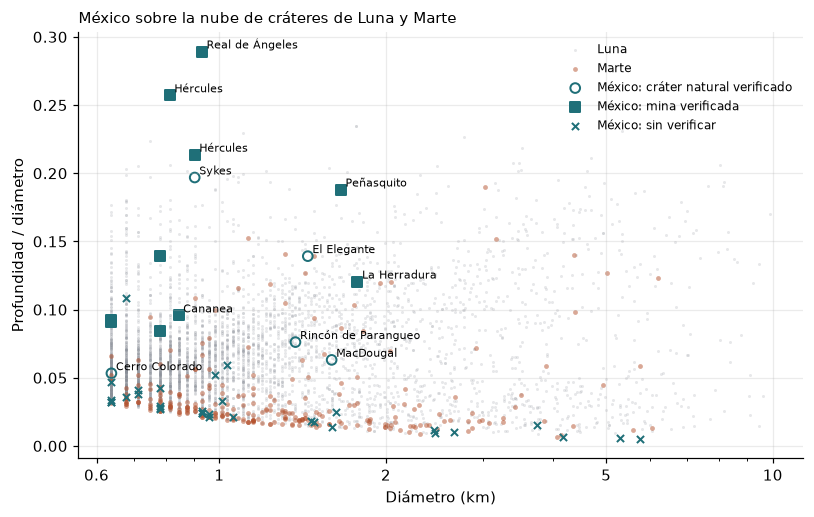

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for c, s, a in [("Luna", 4, .2), ("Marte", 10, .5)]:
    d = lm[lm.cuerpo == c]; ax.scatter(10 ** d.log_diam, d.prof_diam, s=s, alpha=a, color=COLORES[c], lw=0, label=c)
for g_, mk in [("cráter natural verificado", "o"), ("mina verificada", "s"), ("sin verificar", "x")]:
    d = mx_a[mx_a.grupo_val == g_]
    ax.scatter(d.diam_km, d.prof_diam, s=40 if mk != "x" else 22, marker=mk, color=COLORES["Tierra"],
               facecolors="none" if mk == "o" else None, lw=1.3, label=f"México: {g_}")
    for _, p in d[d.nombre.notna()].iterrows():
        ax.annotate(p.nombre.split(" (")[0], (p.diam_km, p.prof_diam), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_xticks([0.6, 1, 2, 5, 10]); ax.set_xticklabels(["0.6", "1", "2", "5", "10"])
ax.set_xlabel("Diámetro (km)"); ax.set_ylabel("Profundidad / diámetro"); ax.legend(frameon=False, fontsize=8)
ax.set_title("México sobre la nube de cráteres de Luna y Marte", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(SALIDA / "mexico_sobre_luna_marte.png", bbox_inches="tight"); plt.show()

## 4. Resumen y siguientes pasos

| Pregunta | Respuesta |
|---|---|
| ¿Desbalance? | Atendido con pesos por clase; sin ellos el modelo solo dice "Luna". El submuestreo no agrega. |
| ¿Etiquetas de la Tierra? | **Es el cuello de botella.** Con 15 verificados sube de ~55 % a ~70 %, pero 10 son minas. |
| ¿Cráteres chicos? | La mitad tiene menos de 20 píxeles; su aspecto es ruido de cuadrícula. El relleno solo sirve para reconocer hoyas terrestres irregulares (dolinas, tajos). Profundidad/diámetro y borde son lo que importa. |
| ¿Anillo lunar? | No estorba. |
| ¿Mejor pregunta? | Luna contra Marte con datos limpios separa ~75 %. Usarlo para juzgar a México no necesita etiquetas terrestres. |

**Lo que dice el puntaje nuevo.** 85 % de los cráteres áridos de México caen dentro de la nube de Luna y Marte: en forma son análogos plausibles. Los que quedan fuera son los más hondos (Real de Ángeles, Hércules, Peñasquito, Sykes): son *más* hondos que casi cualquier cráter lunar de su tamaño, así que la analogía se rompe por exceso, no por falta. Los cráteres naturales verificados salen más lunares que marcianos (El Elegante 0.94, Rincón de Parangueo 0.65), y MacDougal y Cerro Colorado quedan a medio camino.

**Siguientes pasos, en orden de impacto**
1. Etiquetar a mano las 47 detecciones áridas (y separar natural / mina).
2. Agregar variables del perfil del cráter calculadas del modelo de elevación: pendiente de la pared, forma del fondo (taza o plano), continuidad del borde. Es trabajo en el Colab de `analisis/`.
3. Medir a 100 m donde se pueda, para que la forma en planta deje de ser ruido.
4. Revisar si el modelo de Marte (HRSC+MOLA) suaviza los cráteres frente a LOLA y Copernicus: eso bajaría el d/D marciano por instrumento, no por geología.